# Minimum Variance Analysis for selected intervals of Juno Magnetometer data.

In [1]:
import os
import re
import glob
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt

from matplotlib.ticker import AutoMinorLocator

from JunoPy.mag import MagData, mva
from JunoPy.library import find_ticks_between

## 1. Specify epoch and identify the magnetometer file.

In [498]:
start = dt.datetime.strptime('2018-193T02:11:09', '%Y-%jT%H:%M:%S')
end   = dt.datetime.strptime('2018-193T02:12:15', '%Y-%jT%H:%M:%S')

magfile = glob.glob('data/mag/*{:s}ss*.hdf5'.format(start.strftime('%Y%j')))[0]
print('Magnetometer file to plot - {:s}'.format(magfile))

Magnetometer file to plot - data/mag/fgm_jno_l3_2018193ss_v01.hdf5


## 2. Read and crop the magnetometer file (+/- 10 minutes from epoch)

In [499]:
def read_and_crop(magfile, start, end):
    """Read and crop magnetometer data."""
    magdata = MagData(filename=magfile)
    start_cut = start - dt.timedelta(minutes=10)
    end_cut   = end   + dt.timedelta(minutes=10)
    magdata.df = magdata.df.loc[start_cut:end_cut]

    magdata_mva = MagData(filename=magfile)
    magdata_mva.df = magdata_mva.df.loc[start:end]
    magdata_mva = mva(magdata_mva)

    # print(magdata)
    return magdata, magdata_mva

magdata, magdata_mva = read_and_crop(magfile, start, end)

## 3. Create the MVA composite plot.

In [500]:
def plot_mva_composite(magdata, magdata_mva, start, end, savefile=False):

    fig = plt.figure(figsize=(11, 8.5), constrained_layout=False, dpi=300)

    gs1 = fig.add_gridspec(
        nrows=4, ncols=1, top=0.99, bottom=0.55, left=0.15, right=0.7, hspace=0)
    ax_magdata = list()
    for i in range(4):
        ax_magdata.append(fig.add_subplot(gs1[i, 0]))

    gs2 = fig.add_gridspec(
        nrows=3, ncols=1, top=0.45, bottom=0.1, left=0.15, right=0.66, hspace=0)
    ax_mvaB = list()
    for i in range(3):
        ax_mvaB.append(fig.add_subplot(gs2[i, 0]))

    gs3 = fig.add_gridspec(
        nrows=2, ncols=1, top=0.45, bottom=0.1, left=0.67, right=0.9, hspace=0)
    ax_hodo = list()
    for i in range(2):
        ax_hodo.append(fig.add_subplot(gs3[i, 0]))

    gs4 = fig.add_gridspec(
        nrows=1, ncols=1, top=0.9, bottom=0.55, left=0.71, right=0.9)
    ax_text = fig.add_subplot(gs4[0, 0])

    # 1. Plot the mag data +/- 10 min from epoch. ------------------------------------
    ax_magdata = magdata.plot(
        vars=['Br', 'Btheta', 'Bphi', 'Bmag'], axs=ax_magdata)
    timearray, tickstring = find_ticks_between(magdata.df.index[0], magdata.df.index[-1])
    ylabels = ['B$_r$', 'B$_\\theta$', 'B$_\phi$', '|B|']
    for i, a in enumerate(ax_magdata):
        a.set_xticks(timearray)
        a.set_xticklabels(tickstring)
        a.set_ylabel(ylabels[i] + ' (nT)')
        a.set_xlim(magdata.df.index[0], magdata.df.index[-1])
        a.label_outer()
        if start and end:
            a.axvspan(start, end, alpha=0.2, color=[0.2, 0.2, 0.2])
    a.tick_params(axis='x', width=2, rotation=0)
    a.xaxis.label.set_visible(False)


    # 2. Plot the MVA B vectors. -------------------------------------------------------
    ax_mvaB = magdata_mva.plot(vars=['B1', 'B2', 'B3'], axs=ax_mvaB)
    timearray, tickstring = find_ticks_between(magdata_mva.df.index[0], magdata_mva.df.index[-1])
    ylabels = ['B$_1$', 'B$_2$', 'B$_3$']
    for i, a in enumerate(ax_mvaB):
        a.set_xticks(timearray)
        a.set_xticklabels(tickstring, fontdict={'horizontalalignment':'right'})
        a.set_xlim(magdata_mva.df.index[0], magdata_mva.df.index[-1])
        a.set_ylabel(ylabels[i] + ' (nT)')
        a.label_outer()

    a.tick_params(axis='x', width=2, rotation=0)
    a.xaxis.label.set_visible(False)

    # 3. Plot the hodograms. -----------------------------------------------------------
    combo = [['B3', 'B1'],
             ['B3', 'B2']]
    for i, a in enumerate(ax_hodo):
        a.plot(magdata_mva.df[combo[i][0]], magdata_mva.df[combo[i][1]],
               color='k',lw=0.4)
        a.set_xlabel(combo[i][0] + ' (nT)')
        a.set_ylabel(combo[i][1] + ' (nT)')
        a.xaxis.set_minor_locator(AutoMinorLocator())
        a.yaxis.set_minor_locator(AutoMinorLocator())
        a.grid('on', which='minor', lw=0.5, ls='dotted')
        a.grid(color='k', ls='dashed', lw=0.25)
        a.yaxis.tick_right()
        a.yaxis.set_label_position("right")
        
    ax_hodo[0].set_xlabel('B$_3$ (nT)')
    ax_hodo[0].set_ylabel('B$_1$ (nT)')
    ax_hodo[1].set_xlabel('B$_3$ (nT)')
    ax_hodo[1].set_ylabel('B$_2$ (nT)')
    
    # 4. Add Text ----------------------------------------------------------------------
    ax_text.axis('off')

    date = dt.datetime.strptime(start.strftime('%Y-%j'), '%Y-%j')

    text = []
    text.append(dt.datetime.strftime(date, '%Y-%m-%d') + ', DOY={:s}'.format(dt.datetime.strftime(date, '%j')))
    text.append('\n\n')
    text.append('MVA Output:\n--------\n\n')
    text.append('x$_1$ = ({:.2f}, {:.2f}, {:.2f})\n'.format(magdata_mva.x1[0], magdata_mva.x1[1], magdata_mva.x1[2]))
    text.append('x$_2$ = ({:.2f}, {:.2f}, {:.2f})\n'.format(magdata_mva.x2[0], magdata_mva.x2[1], magdata_mva.x2[2]))
    text.append('x$_3$ = ({:.2f}, {:.2f}, {:.2f})\n\n'.format(magdata_mva.x3[0], magdata_mva.x3[1], magdata_mva.x3[2]))
    text.append('--------\n')
    text.append('$\lambda_3$ / $\lambda_2$ = {:.2f}\n'.format(magdata_mva.eigval[2] / magdata_mva.eigval[1]))
    text.append('$\lambda_2$ / $\lambda_1$ = {:.2f}\n'.format(magdata_mva.eigval[1] / magdata_mva.eigval[0]))
    text = ''.join(text)
    ax_text.text(0.5, 0.5, text, horizontalalignment='center', verticalalignment='center',
                 bbox=dict(boxstyle="round",
                   ec=(0.9, 0.9, 0.9),
                   fc=(0.9, 0.9, 0.9),
                   ))
    
    if savefile:
        plotfile = 'out_mva/' + dt.datetime.strftime(start, '%Y-%jT%H:%M:%S')
        fig.savefig(plotfile)
        plt.close(fig)

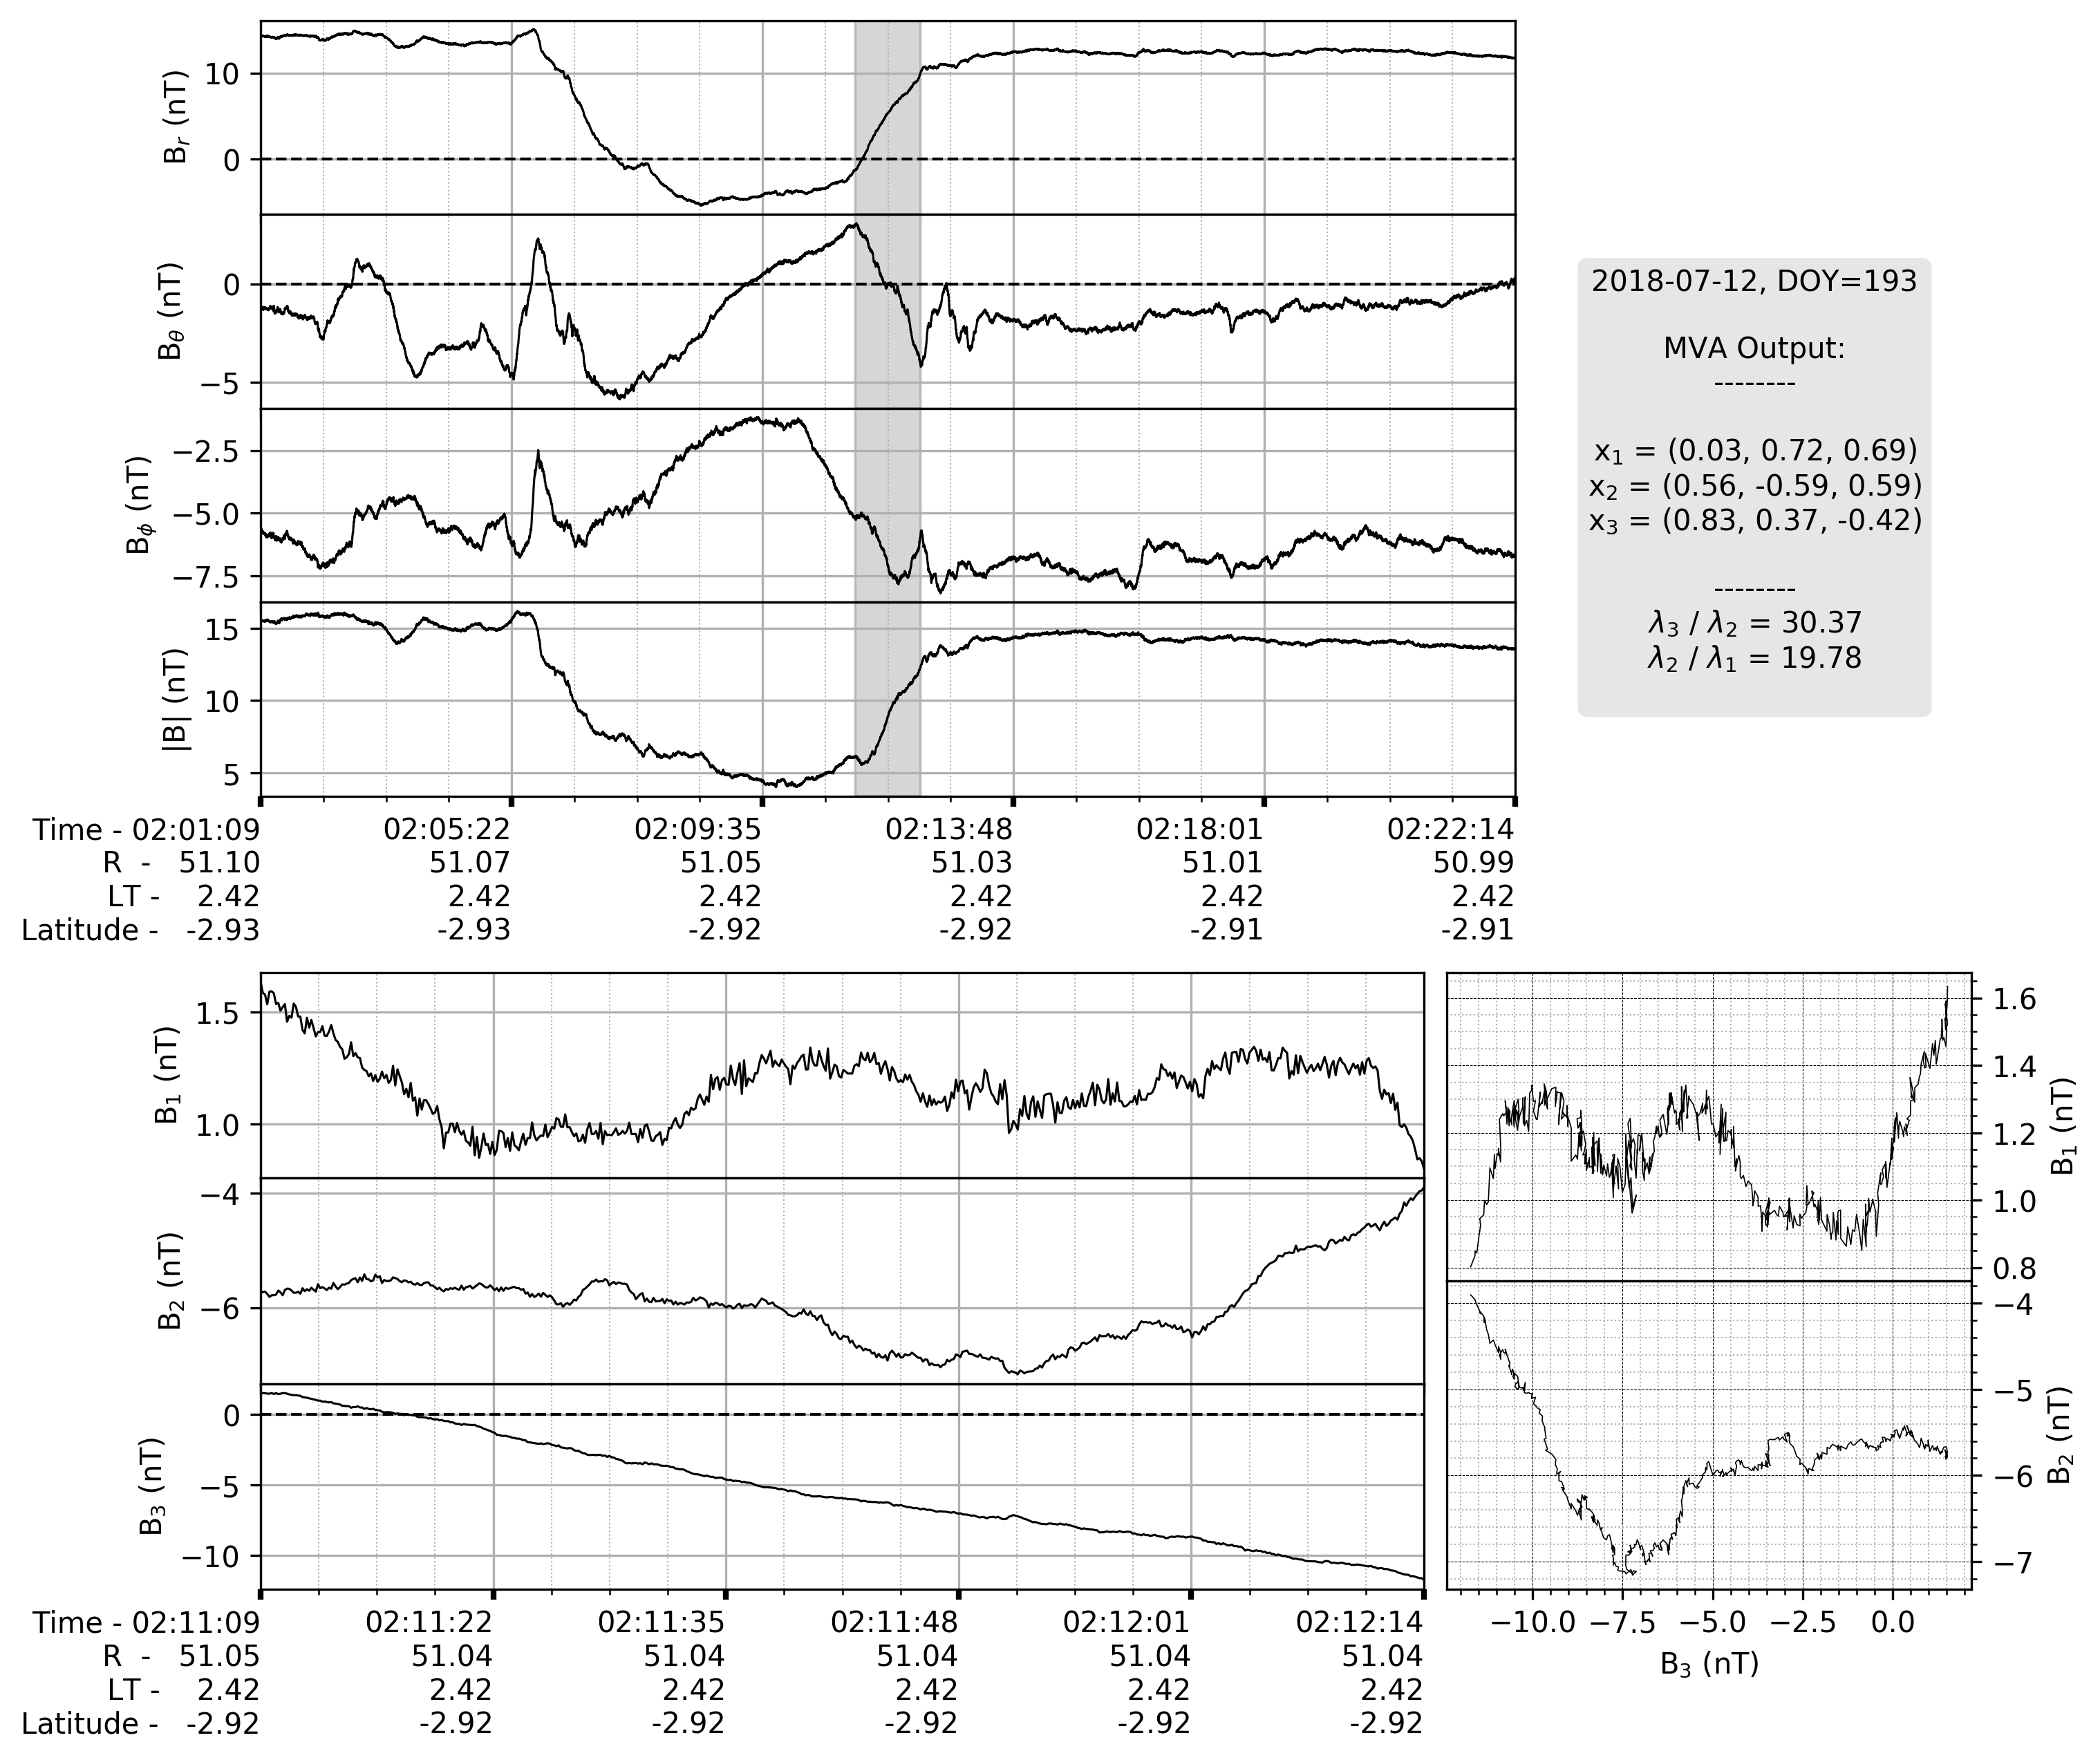

In [501]:
if not os.path.exists('out_mva'):
    os.mkdir('out_mva')
    
plot_mva_composite(magdata, magdata_mva, start, end, savefile=False)

## 4. Create composite plots for all saved epochs.

In [56]:
def save_dates_csv(dates):
    """Save the list of epochs in a csv file with columns - start, end, duration"""
    with open('mva_epochs.csv', 'w') as f:
        f.write('Start,End,Duration\n')
        for date in dates:
            f.write(date.split()[0] + ',')
            f.write(date.split()[-1] + ',')
            start = dt.datetime.strptime(date.split()[0], '%Y-%jT%H:%M:%S')
            end = dt.datetime.strptime(date.split()[-1], '%Y-%jT%H:%M:%S')
            duration = end - start
            f.write('{:.1f}\n'.format(duration.total_seconds()))

In [295]:
dates = [
    "2018-298T01:01:00 2018-298T01:02:15",
    "2018-248T03:29:10 2018-248T03:30:03",
    "2018-246T17:12:10 2018-246T17:12:35",
    "2018-245T15:16:30 2018-245T15:16:57",
    "2018-245T02:30:30 2018-245T02:31:24",
    "2018-136T19:41:20 2018-136T19:42:05",
    "2018-136T12:45:10 2018-136T12:47:30",
    "2018-135T23:08:35 2018-135T23:11:35",
    "2018-085T16:00:17 2018-085T16:01:15",
    "2018-085T15:53:45 2018-085T15:54:15",
    "2018-085T11:35:35 2018-085T11:35:52",
    "2018-085T11:43:33 2018-085T11:43:42",
    "2018-085T11:26:03 2018-085T11:26:12",
    "2018-085T11:17:00 2018-085T11:17:20",
    "2018-085T06:11:25 2018-085T06:12:30",
    "2018-034T22:27:47 2018-034T22:28:55",
    "2018-034T23:48:31 2018-034T23:48:53",
    "2018-034T18:19:34 2018-034T18:19:56",
    "2018-034T13:59:47 2018-034T14:00:25",
    "2018-034T03:37:47 2018-034T03:38:35",
    "2018-301T12:21:42 2018-301T12:21:53",
    "2018-300T10:51:35 2018-300T10:52:15",
    "2018-299T19:13:52 2018-299T19:14:22",
    "2018-299T08:52:20 2018-299T08:52:47",
    "2018-299T05:38:26 2018-299T05:39:29",
    "2018-291T13:03:00 2018-291T13:05:05",
    "2018-291T03:06:42 2018-291T03:08:09",
    "2018-244T20:15:53 2018-244T20:16:25",
    "2018-193T02:07:15 2018-193T02:11:10",
    "2018-191T12:32:57 2018-191T12:34:35",
    "2018-191T10:21:11 2018-191T10:23:13",
    "2018-190T22:27:05 2018-190T22:28:11",
    "2018-190T12:33:12 2018-190T12:33:45",
    
    
    
]

In [296]:
save_dates_csv(dates)

In [486]:
for date in dates:
    start = dt.datetime.strptime(date.split()[0], '%Y-%jT%H:%M:%S')
    end = dt.datetime.strptime(date.split()[-1], '%Y-%jT%H:%M:%S')
    magfile = glob.glob('data/mag/*{:s}ss*.hdf5'.format(start.strftime('%Y%j')))[0]
    magdata, magdata_mva = read_and_crop(magfile, start, end)
    plot_mva_composite(magdata, magdata_mva, start, end, savefile=True)